[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/03_KNN.ipynb)

# 03. Instance-based model: K-Nearest Neighbours
**Run on:** Laptop A · **Approx. runtime:** ~6-10 min (prediction is slow) on a 4-core laptop


**Protocol (same for every model):**
- Each row is one *(GPS point, candidate arc)* pair. The label is 1 if the arc is the point's reference arc.
- **5-fold GroupKFold by trip** on the 78 usable training trips. Each fold fits on a 300k-row sample of points (KNN uses 100k) and is scored on all candidates of the held-out trips.
- The model is then **refit on the training split** and scored on the **10 student-test trips**.
- **Metrics:**
  - macro F1 / precision / recall: candidate level, threshold 0.5
  - log loss
  - **Top-1 accuracy**: the share of GPS points whose highest-scoring candidate is the reference arc
  - continuity
- The **HMM/Viterbi** decoder (parameters in `models/hmm_params.json`) is then run on this model's probabilities to compare *classifier only* with *classifier + HMM*.


**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## KNN


**What it does:** no training. For a new (point, candidate) row it finds the 25 most similar training rows (Euclidean distance on standardised features) and takes a distance-weighted vote.
- **Why tried:** a non-parametric baseline; similar geometric situations should have similar answers.
- **Limitations:**
  - prediction is slow, since it compares against every stored row; we fit on 100k rows to keep it tractable
  - sensitive to feature scaling
  - probabilities are coarse, since they come from votes
- **Hyperparameters:** k = 25, weights = distance, metric = Minkowski (p = 2).
- **Objective:** none (lazy learner).

In [3]:
make_knn = lambda: make_model("knn", SEED)
print(make_knn())
cv_knn = nb.run_cv(make_knn, tr, tr_pts, max_rows=100000)
cv_knn.round(4)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier',
                 KNeighborsClassifier(n_jobs=-1, n_neighbors=25,
                                      weights='distance'))])


  fold 0: F1=0.9044 top1=0.8521 ll=0.2460


  fold 1: F1=0.9193 top1=0.8716 ll=0.1592


  fold 2: F1=0.9048 top1=0.8592 ll=0.2714


  fold 3: F1=0.9406 top1=0.9094 ll=0.1270


  fold 4: F1=0.8997 top1=0.8378 ll=0.2298


CV time 642s | mean macro F1 0.9138 ± 0.0167


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9044,0.8625,0.8245,0.2460,0.8521,95.3445,2.5102,0.1458
1,0.9193,0.8903,0.8354,0.1592,0.8716,140.0796,4.5010,0.1372
2,0.9048,0.8611,0.8371,0.2714,0.8592,125.3789,2.8992,0.1340
3,0.9406,0.9214,0.8812,0.1270,0.9094,133.0119,3.8599,0.2007
4,0.8997,0.8630,0.8013,0.2298,0.8378,144.8291,4.2617,0.1960


In [4]:
model_knn, train_knn, test_knn, p_knn = nb.fit_and_evaluate(make_knn, tr, tr_pts, te, te_pts, max_rows=100000)
print(f"student-test continuity (classifier only): {test_knn['continuity']:.4f} | inference {test_knn['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("KNN", cv_knn, train_knn, test_knn)

fit 0.2s on 100,433 rows
student-test continuity (classifier only): 0.9146 | inference 3.3760 ms/point


KNN,train (fit sample),CV mean (5 folds),student test
macro F1,1.0000,0.9138,0.9124
precision,1.0000,0.8796,0.8676
recall,1.0000,0.8359,0.8404
log loss,0.0000,0.2067,0.1811
Top-1 accuracy,0.9952,0.8660,0.8577


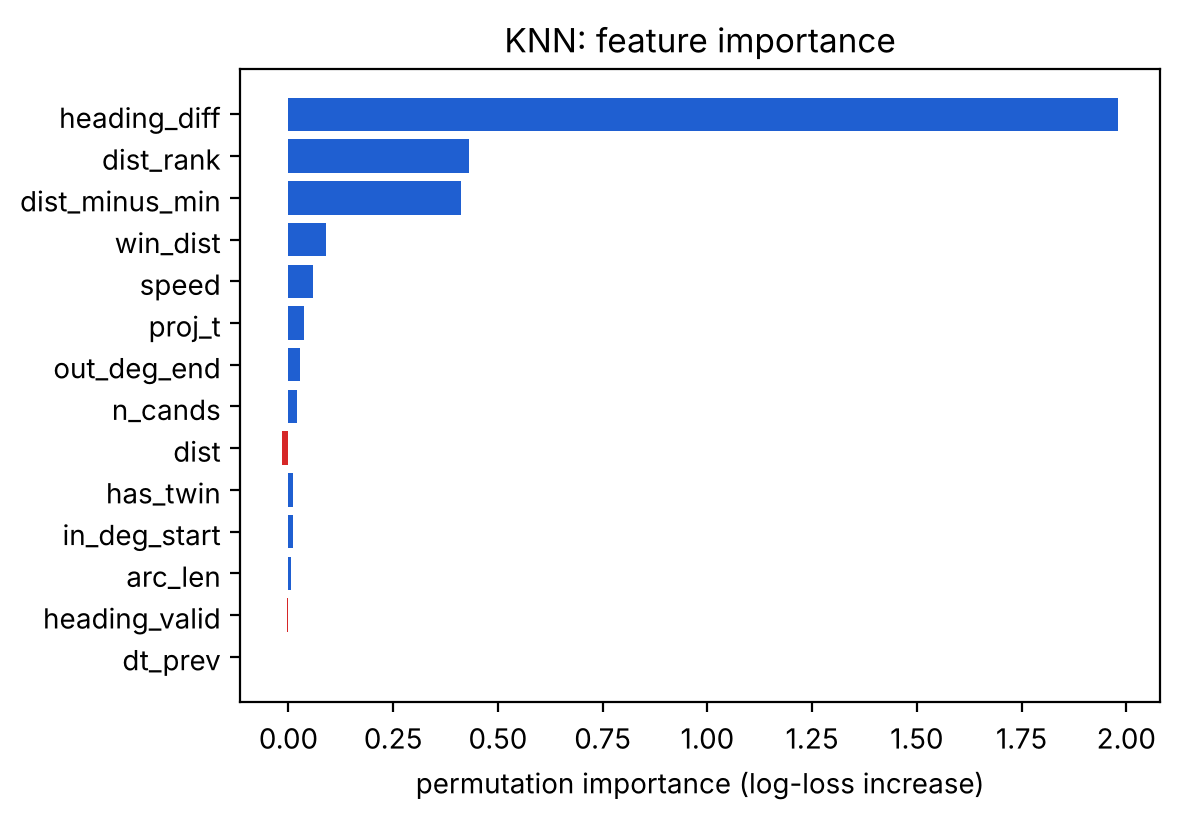

In [5]:
imp_knn = nb.plot_importance(model_knn, te, "KNN")

KNN: mean over 10 trips
cls_top1          0.8713
hmm_top1          0.9143
cls_route_f1      0.7431
hmm_route_f1      0.9498
cls_continuity    0.9146
hmm_continuity    0.9752


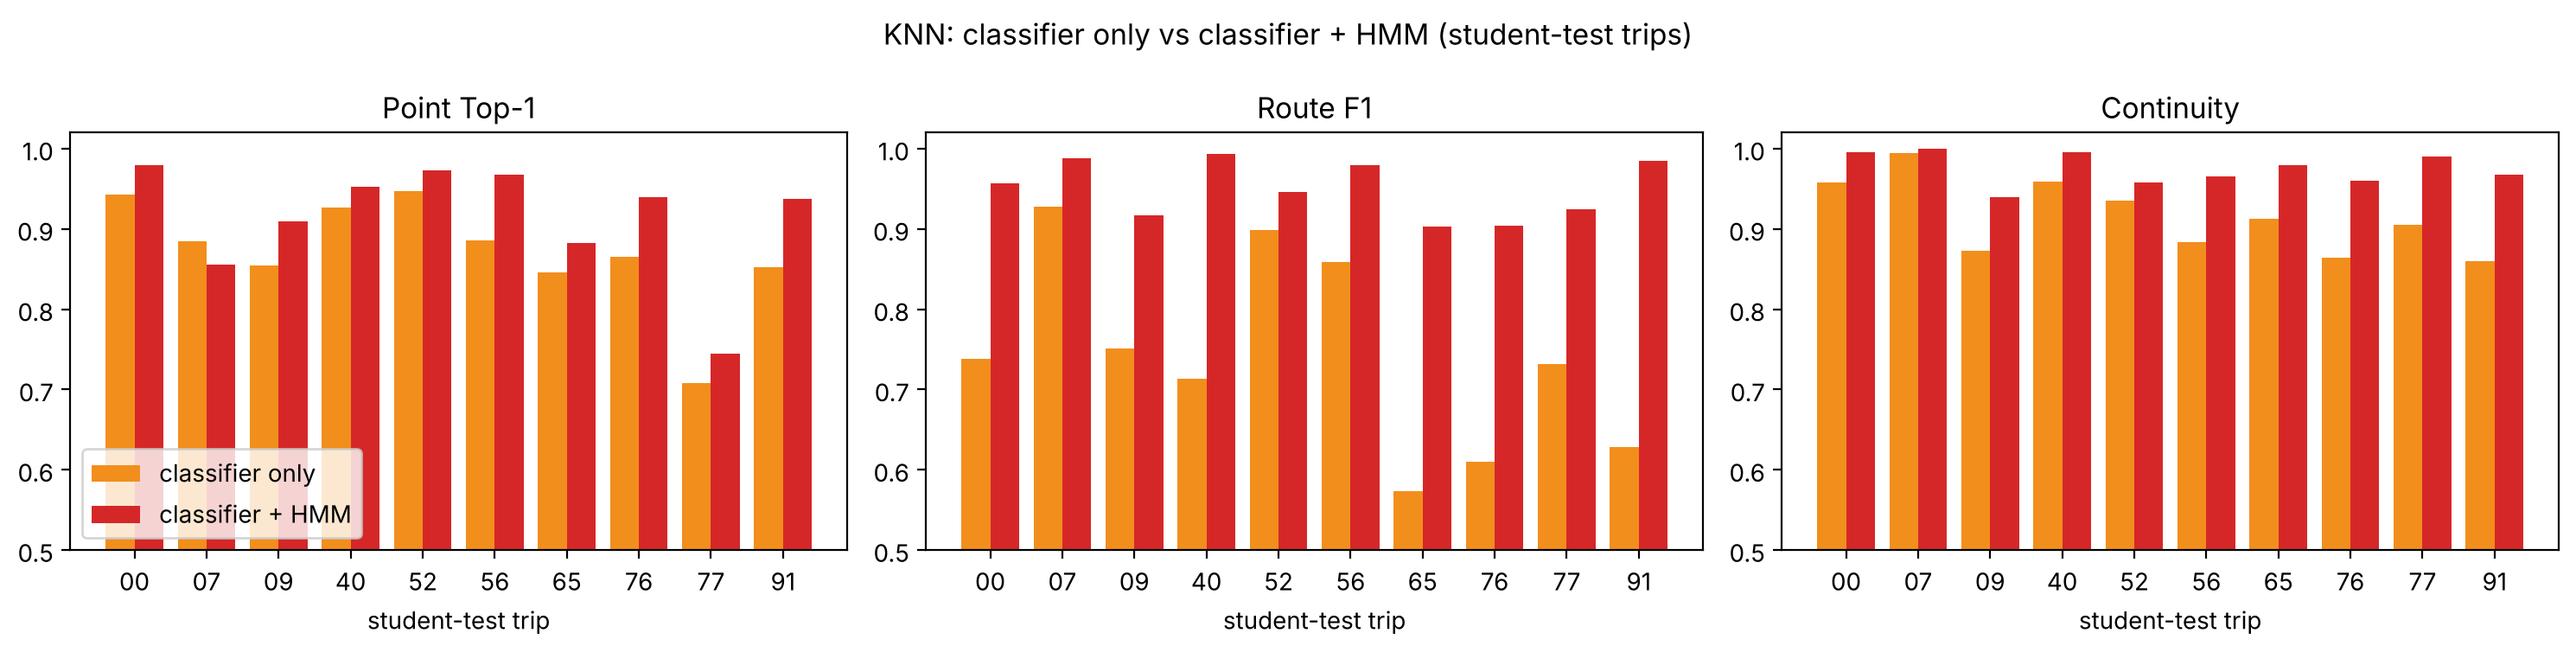

saved results/notebooks/knn.json


In [6]:
hmm_knn = nb.hmm_compare(model_knn, te, "KNN")
nb.plot_hmm(hmm_knn, "KNN: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("knn", cv_knn, train_knn, test_knn,
                {"hmm_mean": hmm_knn.drop(columns=["trip", "model"]).mean().to_dict()})

## Comparison of the models in this notebook

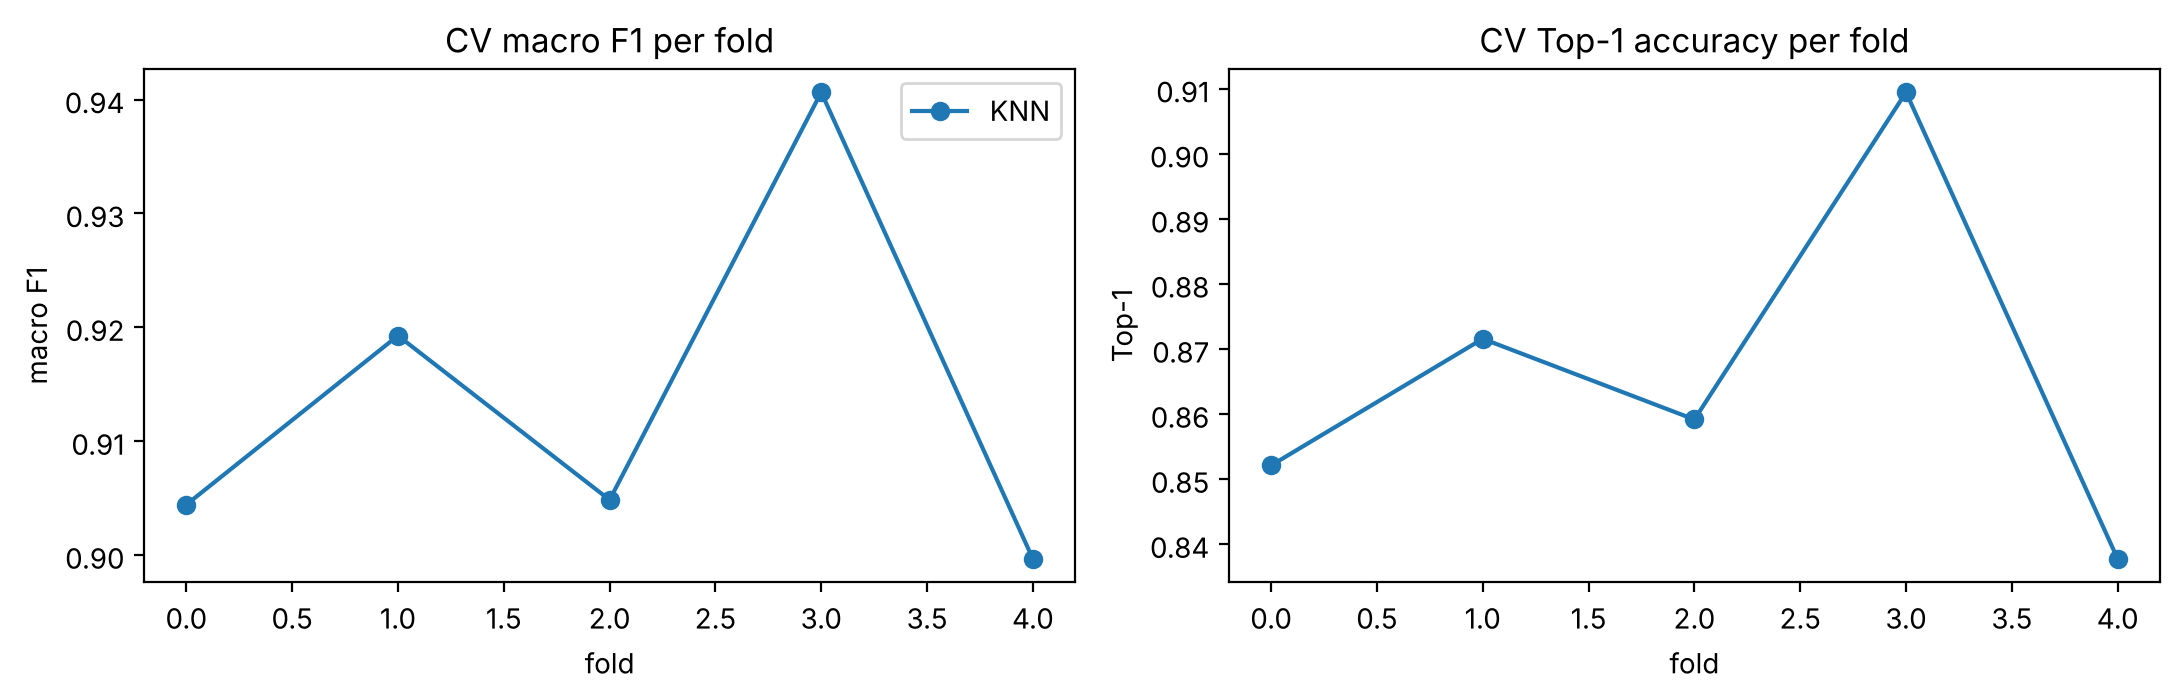

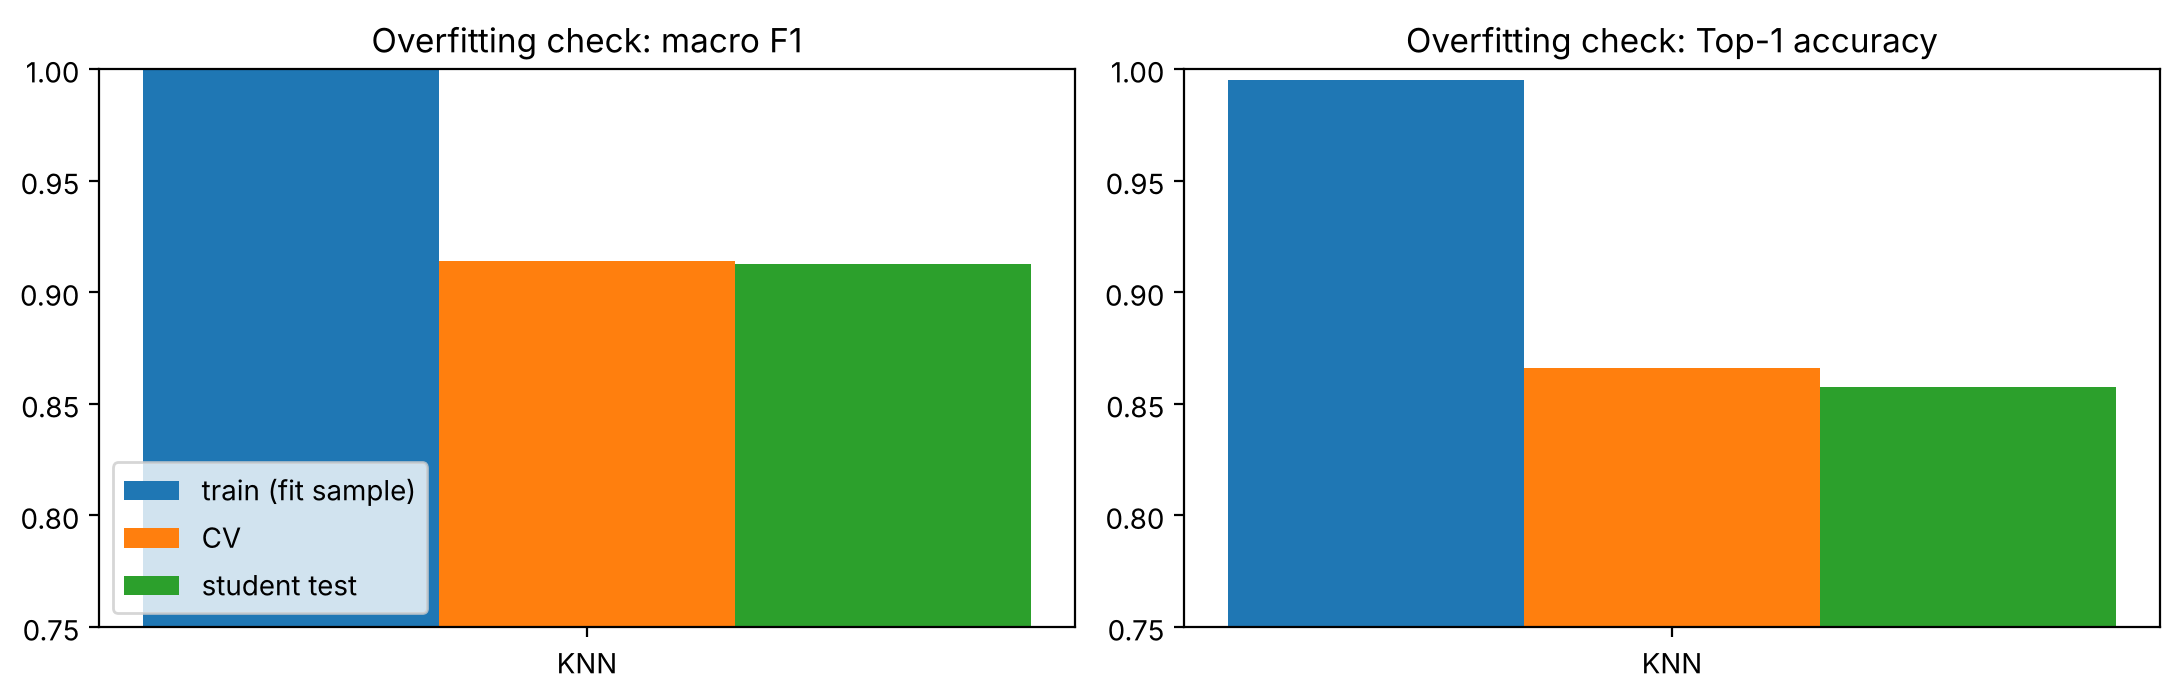

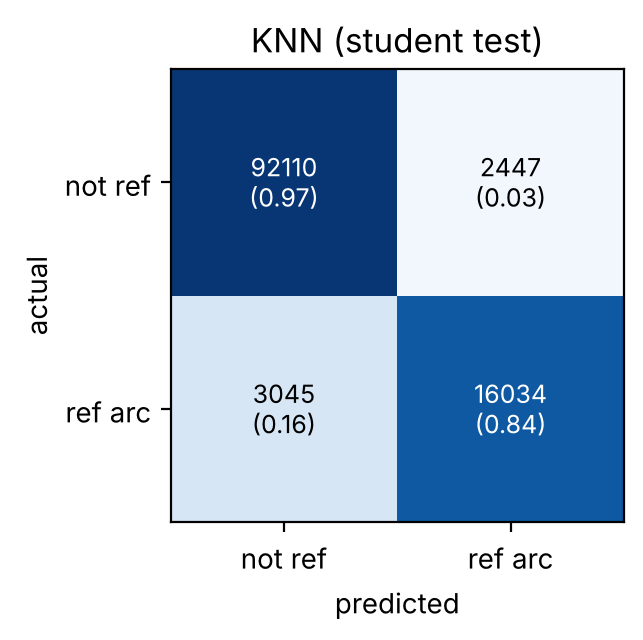

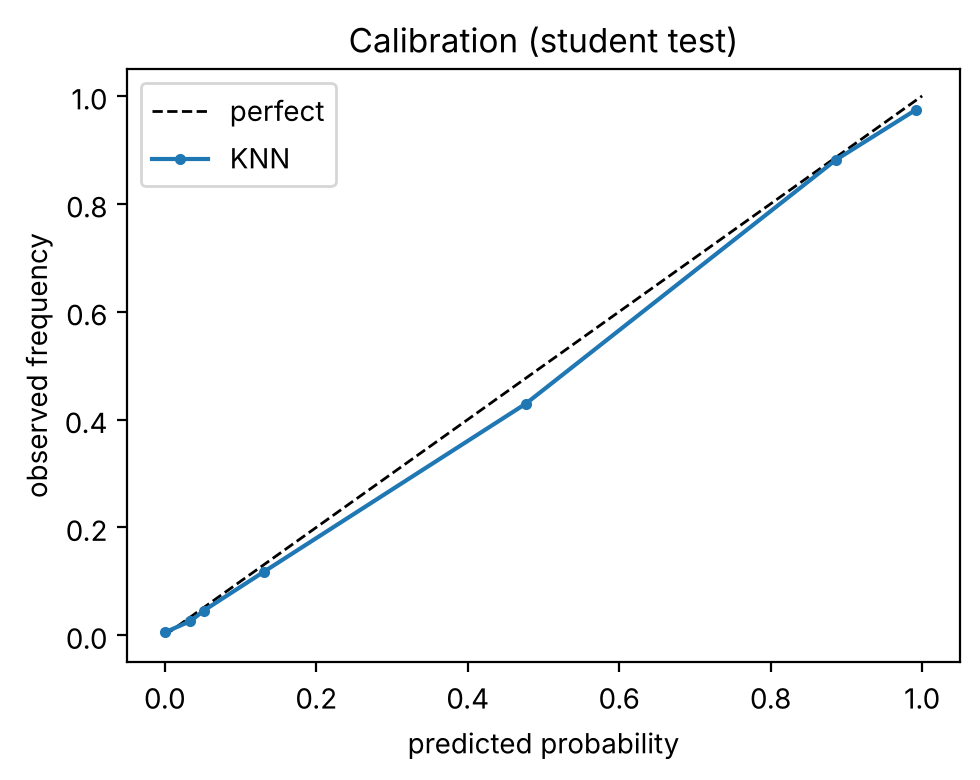

In [7]:
nb.plot_cv_folds({"KNN": cv_knn})
nb.plot_overfit({"KNN": (train_knn, cv_knn, test_knn)})
nb.plot_confusion({"KNN": test_knn["confusion"]})
nb.plot_calibration(te.label.to_numpy(), {"KNN": p_knn})

In [8]:
rows = []
for name, cv, t, h in [("KNN", cv_knn, test_knn, hmm_knn)]:
    rows.append({"model": name, "CV macro F1": cv.macro_f1.mean(), "CV std": cv.macro_f1.std(),
                 "test Top-1": t["top1"], "test macro F1": t["macro_f1"], "test log loss": t["log_loss"],
                 "test continuity": t["continuity"], "Top-1 + HMM (trip mean)": h.hmm_top1.mean(),
                 "route F1 + HMM (trip mean)": h.hmm_route_f1.mean()})
pd.DataFrame(rows).set_index("model").round(4)

,CV macro F1,CV std,test Top-1,test macro F1,test log loss,test continuity,Top-1 + HMM (trip mean),route F1 + HMM (trip mean)
model,,,,,,,,
KNN,0.9138,0.0167,0.8577,0.9124,0.1811,0.9146,0.9143,0.9498
